# Notebook 05: Compare semi-supervised methods

Four semi-supervised methods are trained on the labeled training compounds together with the unlabeled compounds, and compared by grouped cross-validation.

- Labeled data: the `train` compounds of `split.csv`. Unlabeled data (the **pool**): every compound without a family. The holdout is not used here.
- Features: the matrix `X.csv` as extended by notebook 02 (spectrum bins, precursor m/z and the exact-mass features).
- Every method predicts the **family**. The class is derived from the family probabilities in two ways, compared below.
- Main score: macro-F1 over the six drug classes. A drug predicted as `other`, or an `other` compound predicted as a drug, counts as an error.
- Outputs: tables in `reports/tables/`, figures in `reports/figures/05_*.png`, and one saved model per method in `models/`.

## 1. Load the data
### Libraries

In [1]:
import time
from functools import partial

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.semi_supervised import LabelSpreading, SelfTrainingClassifier
from sklearn.svm import SVC

### Plot style
One palette for all figures (blue, orange, aqua, yellow), no top and right frame.

In [2]:
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

### Features
One row per compound, 3,929 columns, as written by notebook 02:
- the spectra of notebook 01: three spectra of 650 bins (LOW, MID, HIGH) and the precursor m/z (1,951 columns);
- group A, mass defect and nitrogen rule (6 columns, `A_`);
- group B, formula features from the precursor mass (10 columns, `B_`);
- group C, neutral losses: three loss spectra of 650 bins (1,950 columns, `C_`);
- group D, spectrum summaries per level (12 columns, `D_`).

All columns lie roughly between -1 and 1. The folds of each cross-validation run in parallel; the whole notebook takes about half an hour on 4 cores.

In [3]:
X_all = pd.read_csv("../data/processed/X.csv", index_col="inchikey")
FEATURE_NAMES = list(X_all.columns)
assert X_all.shape[1] == 3929, "run notebook 02 after notebook 01"
X_all.shape

(1570, 3929)

### Labels and split

In [4]:
labels = pd.read_csv("../data/labels/labels.csv")
split = pd.read_csv("../data/labels/split.csv")
family_to_class = pd.read_csv("../data/labels/family_to_class.csv").set_index("family")["class"].to_dict()

### Training compounds and the pool
The holdout compounds are left out completely.

In [5]:
train = split[split.set == "train"].reset_index(drop=True)
holdout = split[split.set == "holdout"]
pool = labels[labels.status == "unlabeled"]

assert set(pool.inchikey).isdisjoint(split.inchikey)
assert set(holdout.inchikey).isdisjoint(train.inchikey)
len(train), len(holdout), len(pool)

(511, 126, 933)

### Feature matrices

In [6]:
X_train = X_all.loc[train.inchikey].values
X_pool = X_all.loc[pool.inchikey].values
X_train.shape, X_pool.shape

((511, 3929), (933, 3929))

### Families as numbers
Each family gets a number from 0 to 18. Unlabeled compounds get `-1`, the marker scikit-learn uses for "no label".

In [7]:
FAMILIES = sorted(family_to_class)
N_FAMILIES = len(FAMILIES)
y_train = train.family.map({f: i for i, f in enumerate(FAMILIES)}).values
y_pool = np.full(len(pool), -1)

assert (y_train >= 0).all()
N_FAMILIES

19

## 2. Target and scoring
### From families to classes
`M` has one row per family and one column per class, with a 1 where the family belongs to the class.

In [8]:
CLASSES = np.array(sorted(set(family_to_class.values())))
DRUGS = ["cannabinoid", "depressant", "dissociative", "opioid", "psychedelic", "stimulant"]
FAMILY_CLASS = np.array([family_to_class[f] for f in FAMILIES])

M = (FAMILY_CLASS[:, None] == CLASSES[None, :]).astype(float)
pd.DataFrame(M, index=FAMILIES, columns=CLASSES).astype(int)

,cannabinoid,depressant,dissociative,opioid,other,psychedelic,stimulant
amphetamine-type,0,0,0,0,0,0,1
arylcyclohexylamine,0,0,1,0,0,0,0
benzodiazepine,0,1,0,0,0,0,0
cannabinoid-other,1,0,0,0,0,0,0
carboxamide-ester-SC,1,0,0,0,0,0,0
cathinone,0,0,0,0,0,0,1
depressant-other,0,1,0,0,0,0,0
fentanyl-type,0,0,0,1,0,0,0
indole-ketone-SC,1,0,0,0,0,0,0
morphinan,0,0,0,1,0,0,0


### Two ways to get the class
- **sum**: the probability of a class is the sum of the probabilities of its families, and the most likely class wins.
- **top**: the most likely family wins, and its class is the answer.

The two can disagree: two opioid families at 0.25 and 0.20 give opioid 0.45 with **sum**, while a single cathinone at 0.30 wins with **top**.

In [9]:
TARGETS = ["sum", "top"]


def predict_classes(proba, target):
    if target == "sum":
        return CLASSES[(proba @ M).argmax(axis=1)]
    return FAMILY_CLASS[proba.argmax(axis=1)]

### Scores
- `drug_f1`: macro-F1 over the six drug classes. `other` is not averaged, but mistakes involving it count against the drug classes.
- `other_recall`: share of `other` compounds predicted as `other`.
- `family_f1`: macro-F1 over all the families.

In [10]:
true_class = train["class"].values


def score(proba, target):
    pred = predict_classes(proba, target)
    return {
        "drug_f1": f1_score(true_class, pred, labels=DRUGS, average="macro", zero_division=0),
        "other_recall": (pred[true_class == "other"] == "other").mean(),
        "family_f1": f1_score(y_train, proba.argmax(axis=1), average="macro", zero_division=0),
    }

## 3. Shared tools
### Family probabilities from any model
Every method returns a small dictionary. `family_proba` turns it into one probability per family, always in the order of `FAMILIES`. The app uses the same function. Label spreading can leave a compound with no path to any labeled compound (its probabilities are undefined); such a compound gets the same probability for every family.

In [11]:
def align(proba, classes):
    full = np.zeros((len(proba), N_FAMILIES))
    full[:, classes] = proba
    no_path = np.isnan(full).any(axis=1)
    full[no_path] = 1 / N_FAMILIES  # label spreading: no labeled compound reaches this one
    return full


def family_proba(model, X):
    if model["kind"] == "sklearn":
        m = model["model"]
        return align(m.predict_proba(X), m.classes_)
    if model["kind"] == "co-training":
        a, b = model["model_a"], model["model_b"]
        proba_a = align(a.predict_proba(X[:, model["view_a"]]), a.classes_)
        proba_b = align(b.predict_proba(X[:, model["view_b"]]), b.classes_)
        return (proba_a + proba_b) / 2
    if model["kind"] == "cluster-then-label":
        return model["cluster_proba"][model["kmeans"].predict(X)]
    raise ValueError(model["kind"])

### Hiding labels
Used in section 9: keeps a share of the labels in each family (at least one) and turns the rest into `-1`.

In [12]:
def hide_labels(y, fraction, rng):
    y = y.copy()
    for family in np.unique(y):
        members = np.where(y == family)[0]
        keep = max(1, round(fraction * len(members)))
        hidden = rng.choice(members, len(members) - keep, replace=False)
        y[hidden] = -1
    return y

### Grouped cross-validation
For each of the 3 repeats and 5 folds, the model is fitted on the other folds (labeled) plus the pool (unlabeled), then predicts the test fold. The test fold is never part of the pool. The 15 fits (3 repeats x 5 folds) are independent and run in parallel.

In [13]:
FOLD_COLUMNS = ["fold_0", "fold_1", "fold_2"]
N_FOLDS = 5


def fold_data(repeat, fold, fraction):
    test = train[FOLD_COLUMNS[repeat]].values == fold
    y_fit = y_train[~test]
    if fraction < 1:
        y_fit = hide_labels(y_fit, fraction, np.random.default_rng(10 * repeat + fold))
    return np.vstack([X_train[~test], X_pool]), np.concatenate([y_fit, y_pool]), test


def fit_and_predict(fit, X_fit, y_fit, X_test):
    return family_proba(fit(X_fit, y_fit), X_test)


def cross_val_proba(fit, fraction=1.0):
    folds = [(repeat, fold) for repeat in range(len(FOLD_COLUMNS)) for fold in range(N_FOLDS)]
    data = [fold_data(repeat, fold, fraction) for repeat, fold in folds]
    predictions = joblib.Parallel(n_jobs=-1)(
        joblib.delayed(fit_and_predict)(fit, X_fit, y_fit, X_train[test]) for X_fit, y_fit, test in data)
    probas = [np.zeros((len(train), N_FAMILIES)) for _ in FOLD_COLUMNS]
    for (repeat, fold), (_, _, test), proba in zip(folds, data, predictions):
        probas[repeat][test] = proba
    return probas

### Summary of one setting
Each score is computed per repeat; the table shows the mean and the standard deviation (the **spread**) over the 3 repeats.

In [14]:
def summarize(probas):
    rows = []
    for target in TARGETS:
        per_repeat = pd.DataFrame([score(p, target) for p in probas])
        rows.append({
            "target": target,
            "drug_f1": per_repeat.drug_f1.mean(),
            "spread": per_repeat.drug_f1.std(),
            "other_recall": per_repeat.other_recall.mean(),
            "family_f1": per_repeat.family_f1.mean(),
        })
    return rows

## 4. Method 1: self-training
A base classifier is trained on the labeled compounds and predicts the pool. Pool compounds predicted above a confidence threshold receive that family as a pseudo-label and join the training data. This repeats until no new compound passes the threshold.

Three base classifiers are tried, each with a threshold of 0.7 and 0.9.

In [15]:
LOGREG = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
SVM = SVC(C=10, class_weight="balanced", probability=True, random_state=0)
KNN = KNeighborsClassifier(n_neighbors=7, metric="cosine", weights="distance")


def fit_self_training(X, y, base, threshold):
    model = SelfTrainingClassifier(clone(base), threshold=threshold).fit(X, y)
    return {"kind": "sklearn", "model": model}

## 5. Method 2: label spreading
All compounds become points in a graph, each linked to its `k` most similar neighbours. Labels flow along the links until they settle. `alpha` sets how much a labeled compound may move away from its own label (0 keeps it fixed).

The spectra are first reduced to 50 dimensions with PCA, so that distances between neighbours are less noisy.

In [16]:
def fit_label_spreading(X, y, k, alpha):
    model = make_pipeline(
        PCA(n_components=50, random_state=0),
        LabelSpreading(kernel="knn", n_neighbors=k, alpha=alpha, max_iter=1000),
    ).fit(X, y)
    return {"kind": "sklearn", "model": model}

## 6. Method 3: co-training
Each compound is seen through two **views** of the features:
- view A: everything that comes from the LOW and MID spectra (their bins, their neutral losses, their summaries and their mean mass defect);
- view B: everything else, that is the HIGH spectrum (bins, neutral losses, summaries, mean mass defect), the precursor m/z, the precursor mass defect and nitrogen-rule feature, and the formula features.

One logistic regression is trained per view. In each round, each model labels the pool compounds it is most confident about, and those labels are added to the training data of the other model. The final prediction is the average of the two models.

In [17]:
VIEW_A_PREFIXES = ("LOW_", "MID_", "C_LOW_", "C_MID_", "D_LOW_", "D_MID_", "A_peak_defect_LOW", "A_peak_defect_MID")
VIEW_A = np.array([i for i, name in enumerate(FEATURE_NAMES) if name.startswith(VIEW_A_PREFIXES)])
VIEW_B = np.array([i for i, name in enumerate(FEATURE_NAMES) if not name.startswith(VIEW_A_PREFIXES)])
assert set(VIEW_A).isdisjoint(VIEW_B) and len(VIEW_A) + len(VIEW_B) == len(FEATURE_NAMES)
len(VIEW_A), len(VIEW_B)

(2610, 1319)

### One teaching step
The teacher labels the `n` unlabeled compounds (from the student's point of view) it is most confident about.

In [18]:
def teach(teacher, X_view, y_student, n):
    unlabeled = np.where(y_student < 0)[0]
    if len(unlabeled) == 0:
        return y_student
    proba = teacher.predict_proba(X_view[unlabeled])
    most_confident = np.argsort(proba.max(axis=1))[-n:]
    y_new = y_student.copy()
    y_new[unlabeled[most_confident]] = teacher.classes_[proba[most_confident].argmax(axis=1)]
    return y_new

### Co-training loop

In [19]:
def fit_co_training(X, y, rounds=10, per_round=20):
    y_a, y_b = y.copy(), y.copy()
    for _ in range(rounds):
        model_a = clone(LOGREG).fit(X[y_a >= 0][:, VIEW_A], y_a[y_a >= 0])
        model_b = clone(LOGREG).fit(X[y_b >= 0][:, VIEW_B], y_b[y_b >= 0])
        y_b = teach(model_a, X[:, VIEW_A], y_b, per_round)
        y_a = teach(model_b, X[:, VIEW_B], y_a, per_round)

    model_a = clone(LOGREG).fit(X[y_a >= 0][:, VIEW_A], y_a[y_a >= 0])
    model_b = clone(LOGREG).fit(X[y_b >= 0][:, VIEW_B], y_b[y_b >= 0])
    return {"kind": "co-training", "model_a": model_a, "model_b": model_b,
            "view_a": VIEW_A, "view_b": VIEW_B}

## 7. Method 4: cluster-then-label
All compounds, labeled and unlabeled, are grouped into clusters with KMeans. Each cluster receives the family shares of its labeled members. A new compound gets the shares of its nearest cluster. A cluster with no labeled member copies the nearest cluster that has one.

In [20]:
def fit_cluster_then_label(X, y, n_clusters):
    kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit(X)
    counts = np.zeros((n_clusters, N_FAMILIES))
    for cluster, family in zip(kmeans.labels_[y >= 0], y[y >= 0]):
        counts[cluster, family] += 1

    labeled = counts.sum(axis=1) > 0
    centers = kmeans.cluster_centers_
    for cluster in np.where(~labeled)[0]:
        distances = np.linalg.norm(centers[labeled] - centers[cluster], axis=1)
        counts[cluster] = counts[labeled][distances.argmin()]

    cluster_proba = counts / counts.sum(axis=1, keepdims=True)
    return {"kind": "cluster-then-label", "kmeans": kmeans, "cluster_proba": cluster_proba}

## 8. Compare the methods
### Settings

In [21]:
SETTINGS = [
    ("self-training", "logreg, threshold 0.7", partial(fit_self_training, base=LOGREG, threshold=0.7)),
    ("self-training", "logreg, threshold 0.9", partial(fit_self_training, base=LOGREG, threshold=0.9)),
    ("self-training", "svm, threshold 0.7", partial(fit_self_training, base=SVM, threshold=0.7)),
    ("self-training", "svm, threshold 0.9", partial(fit_self_training, base=SVM, threshold=0.9)),
    ("self-training", "knn, threshold 0.7", partial(fit_self_training, base=KNN, threshold=0.7)),
    ("self-training", "knn, threshold 0.9", partial(fit_self_training, base=KNN, threshold=0.9)),
    ("label-spreading", "k 7, alpha 0.2", partial(fit_label_spreading, k=7, alpha=0.2)),
    ("label-spreading", "k 7, alpha 0.8", partial(fit_label_spreading, k=7, alpha=0.8)),
    ("label-spreading", "k 15, alpha 0.2", partial(fit_label_spreading, k=15, alpha=0.2)),
    ("label-spreading", "k 15, alpha 0.8", partial(fit_label_spreading, k=15, alpha=0.8)),
    ("co-training", "10 rounds, 20 per round", partial(fit_co_training, rounds=10, per_round=20)),
    ("cluster-then-label", "40 clusters", partial(fit_cluster_then_label, n_clusters=40)),
    ("cluster-then-label", "80 clusters", partial(fit_cluster_then_label, n_clusters=80)),
]
fit_of = {(method, setting): fit for method, setting, fit in SETTINGS}
len(SETTINGS)

13

### Run every setting
This is the slow cell (self-training with an SVM takes the longest).

In [22]:
rows = []
oof = {}
for method, setting, fit in SETTINGS:
    start = time.time()
    oof[(method, setting)] = cross_val_proba(fit)
    for row in summarize(oof[(method, setting)]):
        rows.append({"method": method, "setting": setting, **row})
    print(f"{method:20} {setting:25} {time.time() - start:6.0f} s")

results = pd.DataFrame(rows)

self-training        logreg, threshold 0.7        105 s
self-training        logreg, threshold 0.9         77 s
self-training        svm, threshold 0.7           642 s
self-training        svm, threshold 0.9           159 s
self-training        knn, threshold 0.7             6 s
self-training        knn, threshold 0.9             8 s


/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


label-spreading      k 7, alpha 0.2                 4 s


/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


label-spreading      k 7, alpha 0.8                 4 s
label-spreading      k 15, alpha 0.2                4 s
label-spreading      k 15, alpha 0.8                4 s
co-training          10 rounds, 20 per round       83 s
cluster-then-label   40 clusters                   48 s
cluster-then-label   80 clusters                   94 s


### Results table

In [23]:
results.to_csv("../reports/tables/cv_methods.csv", index=False)
results.sort_values("drug_f1", ascending=False).round(3)

,method,setting,target,drug_f1,spread,other_recall,family_f1
2,self-training,"logreg, threshold 0.9",sum,0.806,0.013,0.514,0.715
20,co-training,"10 rounds, 20 per round",sum,0.798,0.008,0.486,0.720
0,self-training,"logreg, threshold 0.7",sum,0.797,0.007,0.528,0.702
21,co-training,"10 rounds, 20 per round",top,0.796,0.006,0.556,0.720
3,self-training,"logreg, threshold 0.9",top,0.796,0.016,0.560,0.715
1,self-training,"logreg, threshold 0.7",top,0.784,0.010,0.551,0.702
6,self-training,"svm, threshold 0.9",sum,0.782,0.012,0.727,0.710
7,self-training,"svm, threshold 0.9",top,0.782,0.010,0.810,0.710
4,self-training,"svm, threshold 0.7",sum,0.780,0.004,0.727,0.697
5,self-training,"svm, threshold 0.7",top,0.776,0.007,0.769,0.697


### Best setting of each method

In [24]:
best = results.loc[results.groupby("method").drug_f1.idxmax()].sort_values("drug_f1", ascending=False)
best.round(3)

,method,setting,target,drug_f1,spread,other_recall,family_f1
2,self-training,"logreg, threshold 0.9",sum,0.806,0.013,0.514,0.715
20,co-training,"10 rounds, 20 per round",sum,0.798,0.008,0.486,0.720
13,label-spreading,"k 7, alpha 0.2",top,0.691,0.004,0.421,0.618
24,cluster-then-label,80 clusters,sum,0.587,0.048,0.301,0.497


### sum against top

In [25]:
results.pivot_table(index=["method", "setting"], columns="target", values="drug_f1").round(3)

target                                        sum    top
method             setting                              
cluster-then-label 40 clusters              0.521  0.506
                   80 clusters              0.587  0.585
co-training        10 rounds, 20 per round  0.798  0.796
label-spreading    k 15, alpha 0.2          0.639  0.659
                   k 15, alpha 0.8          0.596  0.610
                   k 7, alpha 0.2           0.677  0.691
                   k 7, alpha 0.8           0.656  0.666
self-training      knn, threshold 0.7       0.648  0.658
                   knn, threshold 0.9       0.660  0.661
                   logreg, threshold 0.7    0.797  0.784
                   logreg, threshold 0.9    0.806  0.796
                   svm, threshold 0.7       0.780  0.776
                   svm, threshold 0.9       0.782  0.782

### Chart

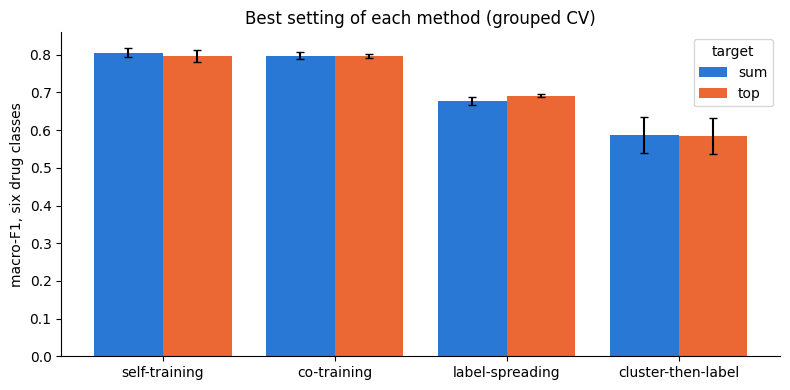

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
chart = results.loc[results.groupby(["method", "target"]).drug_f1.idxmax()]
for shift, target in [(-0.2, "sum"), (0.2, "top")]:
    part = chart[chart.target == target].set_index("method").reindex(best.method)
    ax.bar(np.arange(len(part)) + shift, part.drug_f1, width=0.4, yerr=part.spread, label=target, capsize=3)
ax.set_xticks(range(len(best)), best.method)
ax.set_ylabel("macro-F1, six drug classes")
ax.set_title("Best setting of each method (grouped CV)")
ax.legend(title="target")
fig.tight_layout()
fig.savefig("../reports/figures/05_methods.png", dpi=150, bbox_inches="tight")

### F1 per class for the best setting of each method

In [27]:
per_class = {}
for _, row in best.iterrows():
    probas = oof[(row.method, row.setting)]
    f1 = [f1_score(true_class, predict_classes(p, row.target), labels=list(CLASSES), average=None) for p in probas]
    per_class[row.method] = np.mean(f1, axis=0)

per_class = pd.DataFrame(per_class, index=CLASSES)
per_class.to_csv("../reports/tables/cv_per_class.csv")
per_class.round(2)

,self-training,co-training,label-spreading,cluster-then-label
cannabinoid,0.86,0.85,0.75,0.64
depressant,0.73,0.71,0.66,0.48
dissociative,0.79,0.82,0.56,0.45
opioid,0.81,0.81,0.74,0.64
other,0.49,0.47,0.38,0.30
psychedelic,0.80,0.77,0.76,0.63
stimulant,0.84,0.82,0.68,0.67


## 9. Fewer labels
The best setting of each method is run again with 10%, 20% and 50% of the training labels; the hidden labels join the pool. This shows how much each method depends on the number of labels.

In [28]:
FRACTIONS = [0.1, 0.2, 0.5, 1.0]
rows = []
for _, row in best.iterrows():
    for fraction in FRACTIONS:
        if fraction == 1.0:
            probas = oof[(row.method, row.setting)]
        else:
            probas = cross_val_proba(fit_of[(row.method, row.setting)], fraction)
        scores = [score(p, row.target)["drug_f1"] for p in probas]
        rows.append({"method": row.method, "fraction": fraction,
                     "drug_f1": np.mean(scores), "spread": np.std(scores, ddof=1)})
        print(f"{row.method:20} {fraction:4.0%}  {np.mean(scores):.3f}")

fractions = pd.DataFrame(rows)
fractions.to_csv("../reports/tables/label_fractions.csv", index=False)

self-training         10%  0.482
self-training         20%  0.593
self-training         50%  0.718
self-training        100%  0.806
co-training           10%  0.459
co-training           20%  0.571
co-training           50%  0.727
co-training          100%  0.798


/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_prop

label-spreading       10%  0.468


/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


label-spreading       20%  0.558


/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
/home/solaire/.local/lib/python3.10/site-packages/sklearn/semi_supervised/_label_propagation.py:230: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


label-spreading       50%  0.635
label-spreading      100%  0.691
cluster-then-label    10%  0.423
cluster-then-label    20%  0.478
cluster-then-label    50%  0.541
cluster-then-label   100%  0.587


### Chart

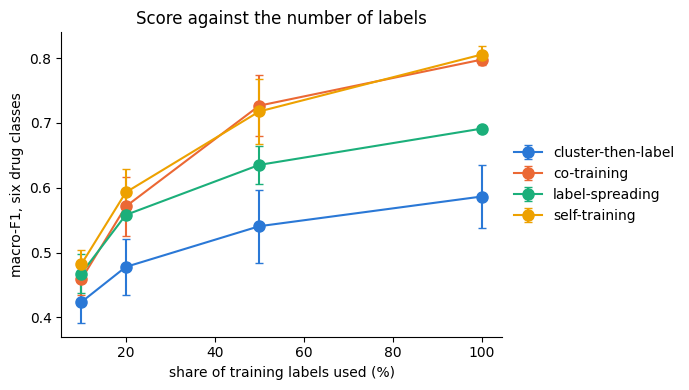

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
for method, part in fractions.groupby("method"):
    ax.errorbar(part.fraction * 100, part.drug_f1, yerr=part.spread, marker="o", markersize=8, capsize=3, label=method)
ax.set_xlabel("share of training labels used (%)")
ax.set_ylabel("macro-F1, six drug classes")
ax.set_title("Score against the number of labels")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
fig.tight_layout()
fig.savefig("../reports/figures/05_label_fractions.png", dpi=150, bbox_inches="tight")

## 10. Winner
The setting with the best `drug_f1` wins. Settings within one spread of it are treated as equal, and among them the simplest method wins (order below), then **sum** before **top**.

In [30]:
SIMPLEST_FIRST = ["cluster-then-label", "self-training", "label-spreading", "co-training"]

top_row = results.loc[results.drug_f1.idxmax()]
close = results[results.drug_f1 >= top_row.drug_f1 - top_row.spread].copy()
close["rank"] = close.method.map(SIMPLEST_FIRST.index)
close["target_rank"] = close.target.map(TARGETS.index)
winner = close.sort_values(["rank", "target_rank", "drug_f1"], ascending=[True, True, False]).iloc[0]

winner[["method", "setting", "target", "drug_f1", "spread", "other_recall", "family_f1"]]

method                  self-training
setting         logreg, threshold 0.9
target                            sum
drug_f1                      0.805694
spread                       0.012874
other_recall                 0.513889
family_f1                    0.715025
Name: 2, dtype: object

In [31]:
winner[["method", "setting", "target", "drug_f1", "spread"]].to_frame().T.to_csv(
    "../reports/tables/winner.csv", index=False)

### Out-of-fold probabilities of the winner
Saved for notebook 06, which chooses the confidence threshold from them (one block of rows per repeat).

In [32]:
oof_winner = pd.concat([
    pd.DataFrame(proba, columns=FAMILIES).assign(inchikey=train.inchikey, repeat=repeat)
    for repeat, proba in enumerate(oof[(winner.method, winner.setting)])])
oof_winner.to_csv("../reports/tables/oof_winner.csv", index=False)
oof_winner.shape

(1533, 21)

## 11. Save the models
The best setting of each method is fitted again on all training compounds plus the pool, and saved to `models/<method>.joblib`. Every file holds the same keys, so the app loads any of them the same way and calls `family_proba` on the `model` entry.

In [33]:
X_final = np.vstack([X_train, X_pool])
y_final = np.concatenate([y_train, y_pool])

fitted = {}
for _, row in best.iterrows():
    model = fit_of[(row.method, row.setting)](X_final, y_final)
    saved = {
        "method": row.method,
        "setting": row.setting,
        "target": row.target,
        "classes": list(CLASSES),
        "families": FAMILIES,
        "family_to_class": family_to_class,
        "feature_names": FEATURE_NAMES,
        "model": model,
    }
    fitted[row.method] = model
    joblib.dump(saved, f"../models/{row.method.replace('-', '_')}.joblib")
    print("saved", row.method)

saved self-training
saved co-training
saved label-spreading
saved cluster-then-label


### Check the saved files
Each file is loaded back and must give the same probabilities as the model in memory, with one row summing to 1 per compound.

In [34]:
for method in best.method:
    saved = joblib.load(f"../models/{method.replace('-', '_')}.joblib")
    proba = family_proba(saved["model"], X_train[:5])
    assert saved["families"] == FAMILIES and saved["feature_names"] == FEATURE_NAMES
    assert np.allclose(proba, family_proba(fitted[method], X_train[:5]))
    assert np.allclose(proba.sum(axis=1), 1)
    print(method, predict_classes(proba, saved["target"]))

self-training ['stimulant' 'stimulant' 'stimulant' 'stimulant' 'stimulant']
co-training ['stimulant' 'stimulant' 'stimulant' 'stimulant' 'stimulant']
label-spreading ['stimulant' 'stimulant' 'stimulant' 'stimulant' 'stimulant']
cluster-then-label ['stimulant' 'stimulant' 'stimulant' 'stimulant' 'stimulant']


## 12. Summary

In [35]:
print(f"winner: {winner.method} ({winner.setting}, target {winner.target})")
print(f"drug macro-F1 {winner.drug_f1:.3f} +/- {winner.spread:.3f}, other recall {winner.other_recall:.2f}")
best[["method", "setting", "target", "drug_f1", "spread"]].round(3)

winner: self-training (logreg, threshold 0.9, target sum)
drug macro-F1 0.806 +/- 0.013, other recall 0.51


,method,setting,target,drug_f1,spread
2,self-training,"logreg, threshold 0.9",sum,0.806,0.013
20,co-training,"10 rounds, 20 per round",sum,0.798,0.008
13,label-spreading,"k 7, alpha 0.2",top,0.691,0.004
24,cluster-then-label,80 clusters,sum,0.587,0.048
